# W7D5_LAB_In_God_we_trust_everyone_else_bring_the_data
- Week 7 / Day 5
- Student: Andreas Papachristophorou
- Course: AI Consulting & Integration 2026-07
- Date: 2026-08-24
---

## Step 1: Find and Select a Dataset


## Dataset Selection

### Dataset Name
Digital Marketing Campaign Dataset

### Source
Kaggle

### Dataset URL
https://www.kaggle.com/datasets/arpit2712/digital-marketing-company/data

### Why This Dataset Was Chosen
This dataset was selected because it contains 8,000 marketing campaign/customer records across five campaign channels: Email, PPC, SEO, Social Media, and Referral. These channels provide multiple comparable groups, which is required for pairwise statistical testing.

The dataset includes useful marketing-performance variables, including advertising spend (`AdSpend`), click-through rate (`ClickThroughRate`), conversion rate (`ConversionRate`), website visits (`WebsiteVisits`), and a binary conversion outcome (`Conversion`). This supports both continuous-metric comparisons using independent t-tests and binary-outcome comparisons using Fisher's exact test.

The dataset does not include revenue, so a genuine Return on Ad Spend (ROAS) calculation is not possible. The analysis will therefore focus on conversion performance, advertising spend, click-through rate, and conversion outcomes. This limitation will be clearly stated in the final executive memo.

Although the dataset is general digital marketing data rather than cruise-industry data, the findings will be interpreted as an illustrative digital customer-acquisition scenario relevant to tourism or cruise marketing. No conclusions will be presented as evidence about a real cruise company.

## Step 2: Load and Explore Your Dataset

In [1]:
import pandas as pd

file_path = "data/digital_marketing_campaign_dataset.csv"

df = pd.read_csv(file_path)

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst five rows:")
display(df.head())

Dataset shape: (8000, 20)

Column names:
['CustomerID', 'Age', 'Gender', 'Income', 'CampaignChannel', 'CampaignType', 'AdSpend', 'ClickThroughRate', 'ConversionRate', 'WebsiteVisits', 'PagesPerVisit', 'TimeOnSite', 'SocialShares', 'EmailOpens', 'EmailClicks', 'PreviousPurchases', 'LoyaltyPoints', 'AdvertisingPlatform', 'AdvertisingTool', 'Conversion']

First five rows:


,CustomerID,Age,Gender,Income,CampaignChannel,CampaignType,AdSpend,ClickThroughRate,ConversionRate,WebsiteVisits,PagesPerVisit,TimeOnSite,SocialShares,EmailOpens,EmailClicks,PreviousPurchases,LoyaltyPoints,AdvertisingPlatform,AdvertisingTool,Conversion
0,8000,56,Female,136912,Social Media,Awareness,6497.870068,0.043919,0.088031,0,2.399017,7.396803,19,6,9,4,688,IsConfid,ToolConfid,1
1,8001,69,Male,41760,Email,Retention,3898.668606,0.155725,0.182725,42,2.917138,5.352549,5,2,7,2,3459,IsConfid,ToolConfid,1
2,8002,46,Female,88456,PPC,Awareness,1546.429596,0.277490,0.076423,2,8.223619,13.794901,0,11,2,8,2337,IsConfid,ToolConfid,1
3,8003,32,Female,44085,PPC,Conversion,539.525936,0.137611,0.088004,47,4.540939,14.688363,89,2,2,0,2463,IsConfid,ToolConfid,1
4,8004,60,Female,83964,PPC,Conversion,1678.043573,0.252851,0.109940,0,2.046847,13.993370,6,6,6,8,4345,IsConfid,ToolConfid,1


In [2]:
# Count how many rows belong to each marketing channel
channel_counts = df["CampaignChannel"].value_counts()

# Print a clear heading before the results
print("Records per marketing channel:")

# Display the count for each channel
print(channel_counts)

Records per marketing channel:
CampaignChannel
Referral        1719
PPC             1655
Email           1557
SEO             1550
Social Media    1519
Name: count, dtype: int64


### Channel Sample Sizes

The dataset contains five campaign channels with relatively balanced sample sizes:

- Referral: 1,719 records
- PPC: 1,655 records
- Email: 1,557 records
- SEO: 1,550 records
- Social Media: 1,519 records

Each channel has more than 1,500 records. This provides sufficient observations for exploratory analysis and pairwise statistical comparisons. Although the group sizes are not identical, the difference between the largest and smallest group is modest, so no channel is severely under-represented.

In [3]:
# List the key columns we plan to use in the analysis
key_columns = [
    "CampaignChannel",
    "AdSpend",
    "ClickThroughRate",
    "ConversionRate",
    "WebsiteVisits",
    "Conversion"
]

# Count missing values in each key column
missing_values = df[key_columns].isna().sum()

# Print a clear heading before the result
print("Missing values in key analysis columns:")

# Display the number of missing values for each selected column
print(missing_values)

Missing values in key analysis columns:
CampaignChannel     0
AdSpend             0
ClickThroughRate    0
ConversionRate      0
WebsiteVisits       0
Conversion          0
dtype: int64


### Missing-Value Check

No missing values were found in the key analysis columns: `CampaignChannel`, `AdSpend`, `ClickThroughRate`, `ConversionRate`, `WebsiteVisits`, and `Conversion`.

Therefore, no missing-value imputation or row removal is required for these variables. All 8,000 records can remain in the analysis.

In [4]:
# Display summary statistics for the main numeric columns
print(df[["AdSpend", "ClickThroughRate", "ConversionRate", "WebsiteVisits"]].describe().round(4))

# Show every unique value found in the binary Conversion column
print("\nUnique values in Conversion:")
print(sorted(df["Conversion"].unique()))

         AdSpend  ClickThroughRate  ConversionRate  WebsiteVisits
count  8000.0000         8000.0000       8000.0000      8000.0000
mean   5000.9448            0.1548          0.1044        24.7516
std    2838.0382            0.0840          0.0549        14.3123
min     100.0548            0.0100          0.0100         0.0000
25%    2523.2212            0.0826          0.0564        13.0000
50%    5013.4400            0.1545          0.1040        25.0000
75%    7407.9894            0.2282          0.1521        37.0000
max    9997.9148            0.3000          0.2000        49.0000

Unique values in Conversion:
[np.int64(0), np.int64(1)]


In [5]:
# Group all records by marketing channel
# Calculate the number of records and the average value of each available performance metric
channel_summary = (
    df.groupby("CampaignChannel")
    .agg(
        Records=("CustomerID", "count"),
        Average_AdSpend=("AdSpend", "mean"),
        Average_CTR=("ClickThroughRate", "mean"),
        Average_ConversionRate=("ConversionRate", "mean"),
        Average_WebsiteVisits=("WebsiteVisits", "mean"),
        Binary_Conversion_Rate=("Conversion", "mean")
    )
    .round(4)
    .sort_values("Average_ConversionRate", ascending=False)
)

# Convert decimal rates to percentages so the final table is easier to read
channel_summary["Average_CTR"] = channel_summary["Average_CTR"] * 100
channel_summary["Average_ConversionRate"] = channel_summary["Average_ConversionRate"] * 100
channel_summary["Binary_Conversion_Rate"] = channel_summary["Binary_Conversion_Rate"] * 100

# Round the percentage columns again after multiplying by 100
channel_summary = channel_summary.round(2)

# Display the completed summary table
print("Marketing Channel Performance Summary:")
display(channel_summary)

Marketing Channel Performance Summary:


,Records,Average_AdSpend,Average_CTR,Average_ConversionRate,Average_WebsiteVisits,Binary_Conversion_Rate
CampaignChannel,,,,,,
Social Media,1519,4965.32,15.55,10.66,25.13,86.83
Email,1557,5055.60,15.56,10.49,24.88,87.03
PPC,1655,4954.22,15.83,10.41,24.16,88.28
SEO,1550,4994.13,15.32,10.35,24.74,87.68
Referral,1719,5034.04,15.17,10.31,24.89,88.31


In [6]:
%pip install matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.


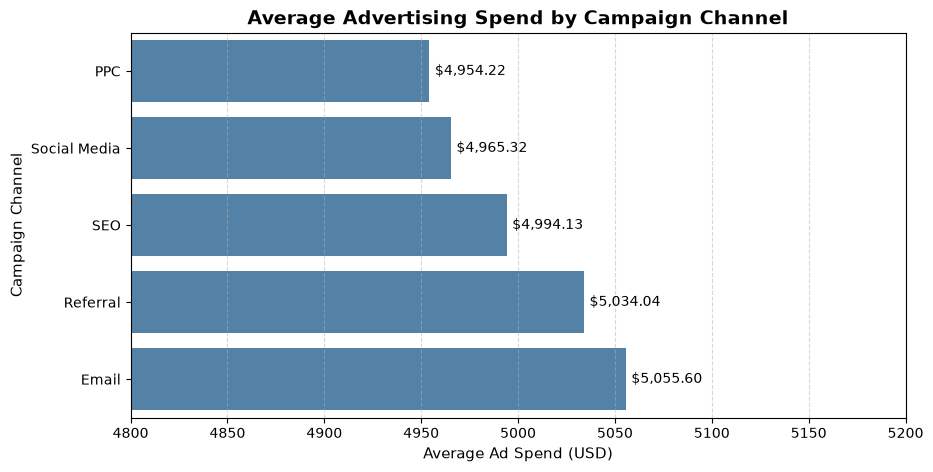

In [18]:
# Import plotting libraries
import matplotlib.pyplot as plt
import seaborn as sns
# Import Path, which helps Python work safely with folders and file paths
from pathlib import Path

# Sort from lowest to highest average spend
ad_spend_plot = channel_summary.sort_values(
    "Average_AdSpend",
    ascending=True
)

# Create a larger figure
plt.figure(figsize=(10, 5))

# Draw the bars
ax = sns.barplot(
    data=ad_spend_plot,
    x="Average_AdSpend",
    y=ad_spend_plot.index,
    color="steelblue"
)

# Zoom the x-axis because all channel averages are close to $5,000
plt.xlim(4800, 5200)

# Add a title and clear labels
plt.title("Average Advertising Spend by Campaign Channel", fontsize=14, weight="bold")
plt.xlabel("Average Ad Spend (USD)", fontsize=11)
plt.ylabel("Campaign Channel", fontsize=11)

# Add light vertical guide lines
plt.grid(axis="x", linestyle="--", alpha=0.5)

# Add the exact dollar value at the end of every bar
for container in ax.containers:
    ax.bar_label(
        container,
        labels=[f"${value:,.2f}" for value in ad_spend_plot["Average_AdSpend"]],
        padding=4
    )


# Create the graphs folder if it does not already exist
Path("graphs").mkdir(exist_ok=True)
# Save the chart inside the graphs subfolder
plt.savefig("graphs/average_ad_spend_by_channel.png", dpi=300)

# Show the chart in the notebook
plt.show()

### Initial observation: average ad spend

Average advertising spend is very similar across all five campaign channels, ranging from approximately $4,954 for PPC to $5,056 for Email. The largest difference is about $101, which is small relative to the overall average spend of about $5,000. This suggests that channel performance differences, if present, are unlikely to be explained by large differences in average ad spend alone. Further statistical testing is required before making budget-allocation recommendations.

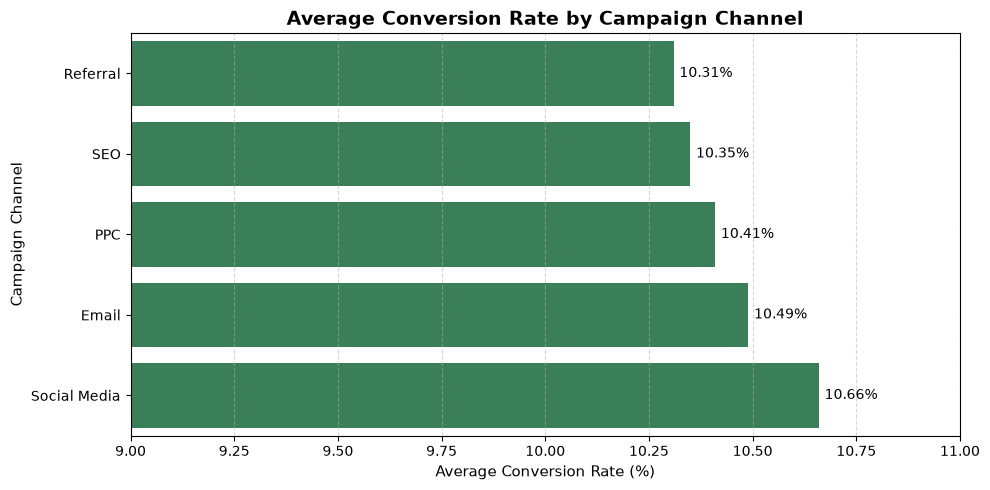

In [19]:
# Sort channels from lowest to highest conversion rate
conversion_rate_plot = channel_summary.sort_values(
    "Average_ConversionRate",
    ascending=True
)

# Create the figure
plt.figure(figsize=(10, 5))

# Create a horizontal bar chart
ax = sns.barplot(
    data=conversion_rate_plot,
    x="Average_ConversionRate",
    y=conversion_rate_plot.index,
    color="seagreen"
)

# Add labels and title
plt.title("Average Conversion Rate by Campaign Channel", fontsize=14, weight="bold")
plt.xlabel("Average Conversion Rate (%)", fontsize=11)
plt.ylabel("Campaign Channel", fontsize=11)

# Zoomed axis highlights small differences; it does not imply large performance gaps
plt.xlim(9, 11)

# Add guide lines
plt.grid(axis="x", linestyle="--", alpha=0.5)

# Put the exact percentage beside each bar
for container in ax.containers:
    ax.bar_label(
        container,
        labels=[
            f"{value:.2f}%"
            for value in conversion_rate_plot["Average_ConversionRate"]
        ],
        padding=4
    )

# Save the chart to the graphs folder
plt.tight_layout()
plt.savefig(
    "graphs/average_conversion_rate_by_channel.png",
    dpi=300,
    bbox_inches="tight"
)

# Display the chart
plt.show()

### Initial observation: average conversion rate

Social Media has the highest average conversion rate at 10.66%, followed by Email at 10.49%. Referral has the lowest average conversion rate at 10.31%.

The overall range across channels is only 0.35 percentage points, from 10.31% to 10.66%. The chart uses a truncated x-axis from 9% to 11% to make these small differences visible; therefore, the visual bar-length differences should not be interpreted as large performance gaps.

At this exploratory stage, the chart shows descriptive differences only. Pairwise t-tests, effect sizes, and multiple-comparisons correction are required before concluding that any channel has a statistically or practically meaningful advantage.

Saving chart to: c:\Users\andre\Documents\IronHack\ACFT_2026_Course\W7D5_LAB_In_God_we_trust_everyone_else_bring_the_data\W7D5_LAB_In_God_we_trust_everyone_else_bring_the_data\lab_statistical_analysis_Andreas_Papachristophorou\graphs\conversion_rate_distributions_by_channel.png
Graphs folder exists: True


FileNotFoundError: [Errno 2] No such file or directory: 'c:\\Users\\andre\\Documents\\IronHack\\ACFT_2026_Course\\W7D5_LAB_In_God_we_trust_everyone_else_bring_the_data\\W7D5_LAB_In_God_we_trust_everyone_else_bring_the_data\\lab_statistical_analysis_Andreas_Papachristophorou\\graphs\\conversion_rate_distributions_by_channel.png'

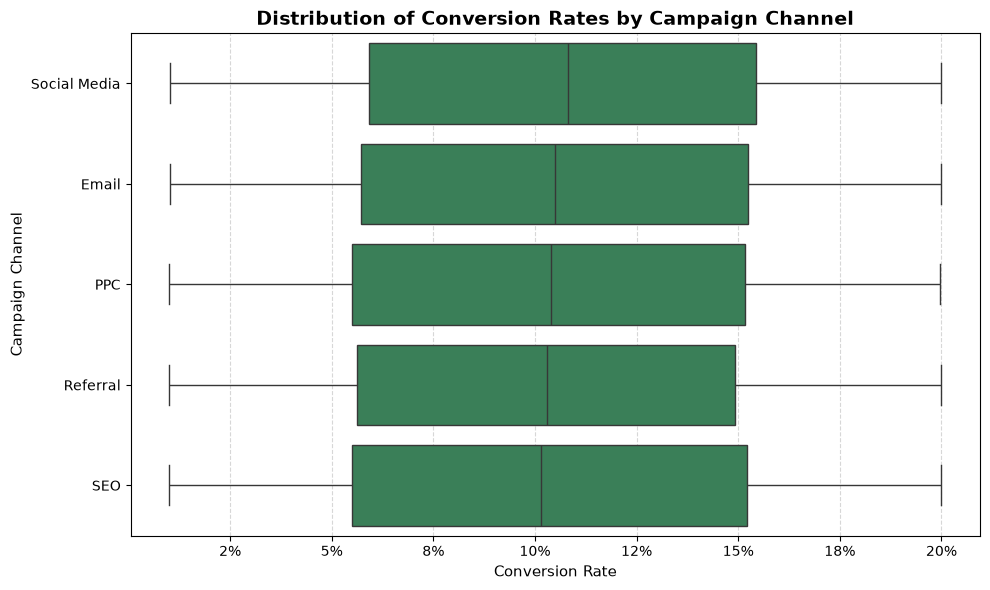

In [31]:
from pathlib import Path

# Create a larger figure for the distribution comparison
plt.figure(figsize=(10, 6))

# Show the spread of individual conversion-rate values in each channel
sns.boxplot(
    data=df,
    x="ConversionRate",
    y="CampaignChannel",
    color="seagreen"
)

# Convert the x-axis from decimals to percentage-style labels
plt.gca().xaxis.set_major_formatter(
    plt.FuncFormatter(lambda value, position: f"{value * 100:.0f}%")
)

# Add a descriptive title and labels
plt.title("Distribution of Conversion Rates by Campaign Channel", fontsize=14, weight="bold")
plt.xlabel("Conversion Rate", fontsize=11)
plt.ylabel("Campaign Channel", fontsize=11)

# Add light guide lines for comparison
plt.grid(axis="x", linestyle="--", alpha=0.5)


# Identify the notebook's current project folder
project_folder = Path.cwd()

# Create the graphs subfolder if needed
graphs_folder = project_folder / "graphs"
graphs_folder.mkdir(parents=True, exist_ok=True)


# Confirm the folder exists before saving
print("Saving chart to:", graphs_folder / "conversion_rate_distributions_by_channel.png")
print("Graphs folder exists:", graphs_folder.exists())

# Save the chart
output_file = graphs_folder / "conversion_rate_distributions_by_channel.png"
output_file.parent.mkdir(parents=True, exist_ok=True)

plt.tight_layout()
# Ensure the destination folder exists immediately before saving
output_file.parent.mkdir(parents=True, exist_ok=True)

plt.savefig(
    str(output_file),
    dpi=300,
    bbox_inches="tight"
)

# Display the chart
plt.show()

### Conversion-rate distribution by channel

This plot compares the distribution of individual conversion-rate observations across the five campaign channels. All five channels show a very similar spread, ranging from approximately 5.5% to 15%, with heavily overlapping interquartile ranges (boxes) and medians clustered close to 10%.

No channel shows a clearly wider or narrower box than the others, and no outliers are visible beyond the whiskers.

This distribution overlap is an important caveat: although average conversion rates differ slightly by channel (10.31% to 10.66%), the huge overlap in individual customer-level conversion rates suggests these small average differences may not be statistically or practically meaningful. Formal statistical testing (t-tests, effect sizes) in the next step will determine whether any of these differences are unlikely to be due to random variation.

In [32]:
# Import the tools needed for continuous-metric comparisons
import numpy as np
from itertools import combinations
from scipy.stats import ttest_ind

# Keep only valid conversion-rate values
conversion_data = df[
    ["CampaignChannel", "ConversionRate"]
].dropna()

# Confirm that each channel has usable observations
conversion_data.groupby("CampaignChannel")["ConversionRate"].agg(
    Records="count",
    Mean="mean",
    Standard_Deviation="std"
).round(4)

,Records,Mean,Standard_Deviation
CampaignChannel,,,
Email,1557,0.1049,0.0549
PPC,1655,0.1041,0.0548
Referral,1719,0.1031,0.0546
SEO,1550,0.1035,0.0552
Social Media,1519,0.1066,0.0549
